In [1]:
from google.colab import drive
drive.mount('/content/drive')
file_path = '/content/drive/MyDrive/TP ML/airbnb-analyse-des-prix-et-leurs-facteurs.ipynb'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
# === Installation ===
!pip -q install scikit-learn pandas matplotlib seaborn statsmodels

# === Imports ===
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import TimeSeriesSplit
import warnings
warnings.filterwarnings('ignore')

GRAINE = 42
np.random.seed(GRAINE)
plt.style.use('seaborn-v0_8-whitegrid')

In [3]:
# === A. Formuler le problème ===
print("""
SUJET F17 — Mises en chantier de logements (Housing Starts)
==========================================================

Intérêt financier :
Les mises en chantier (Housing Starts) sont un indicateur avancé de l’activité
économique américaine. Elles influencent le marché immobilier, les taux d’intérêt,
les valeurs des constructeurs et le cycle économique.

Question :
Peut-on prévoir le nombre de mises en chantier du mois suivant à partir de
l’historique et de la saisonnalité ?

Cible : HOUSTNSA (milliers d’unités, non corrigé des variations saisonnières)
Tâche  : Régression sur série temporelle mensuelle
Métrique de succès fixée AVANT les résultats : MAE < 80 (milliers d’unités)
et battre la référence naïve (persistance saisonnière).
""")


SUJET F17 — Mises en chantier de logements (Housing Starts)

Intérêt financier :
Les mises en chantier (Housing Starts) sont un indicateur avancé de l’activité
économique américaine. Elles influencent le marché immobilier, les taux d’intérêt,
les valeurs des constructeurs et le cycle économique.

Question :
Peut-on prévoir le nombre de mises en chantier du mois suivant à partir de
l’historique et de la saisonnalité ?

Cible : HOUSTNSA (milliers d’unités, non corrigé des variations saisonnières)
Tâche  : Régression sur série temporelle mensuelle
Métrique de succès fixée AVANT les résultats : MAE < 80 (milliers d’unités)
et battre la référence naïve (persistance saisonnière).



In [7]:
# === B. Chargement et description des données ===
# Source officielle : FRED (Federal Reserve Bank of St. Louis)
# Série : HOUSTNSA = New Privately-Owned Housing Units Started (Not Seasonally Adjusted)
# Unité : milliers d’unités
# Fréquence : mensuelle
# Licence : domaine public (données gouvernementales US)
# Date d’extraction : 2026-11 (données jusqu’à oct. 2026)

url = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=HOUSTNSA"
# Utilisation des positions de colonnes (0) pour éviter les erreurs de casse (DATE vs date)
df = pd.read_csv(url, parse_dates=[0], index_col=0)
df.columns = ['housing_starts']

# Conversion en numérique (force les valeurs non valides ou '.' en NaN, puis les supprime)
df['housing_starts'] = pd.to_numeric(df['housing_starts'], errors='coerce')
df = df.dropna()

print("Dimensions :", df.shape)
print("Période :", df.index.min().date(), "→", df.index.max().date())
print("Fréquence : mensuelle")
print("\n5 premières lignes :")
display(df.head())
print("\nStatistiques descriptives :")
display(df.describe().round(1))

# Dictionnaire des variables (5-8 variables utiles)
print("""
Dictionnaire des variables principales :
- housing_starts : cible (milliers d’unités, non SA)
- lag_1, lag_12   : retards (passé uniquement → pas de fuite)
- month_1 … month_11 : variables saisonnières (dummy)
- year            : tendance linéaire
""")

Dimensions : (814, 1)
Période : 1959-01-01 → 2026-10-01
Fréquence : mensuelle

5 premières lignes :


,housing_starts
observation_date,
1959-01-01,96.2
1959-02-01,99.0
1959-03-01,127.7
1959-04-01,150.8
1959-05-01,152.5



Statistiques descriptives :


,housing_starts
count,814.0
mean,119.2
std,36.8
min,31.9
25%,94.7
50%,118.0
75%,142.5
max,234.0



Dictionnaire des variables principales :
- housing_starts : cible (milliers d’unités, non SA)
- lag_1, lag_12   : retards (passé uniquement → pas de fuite)
- month_1 … month_11 : variables saisonnières (dummy)
- year            : tendance linéaire



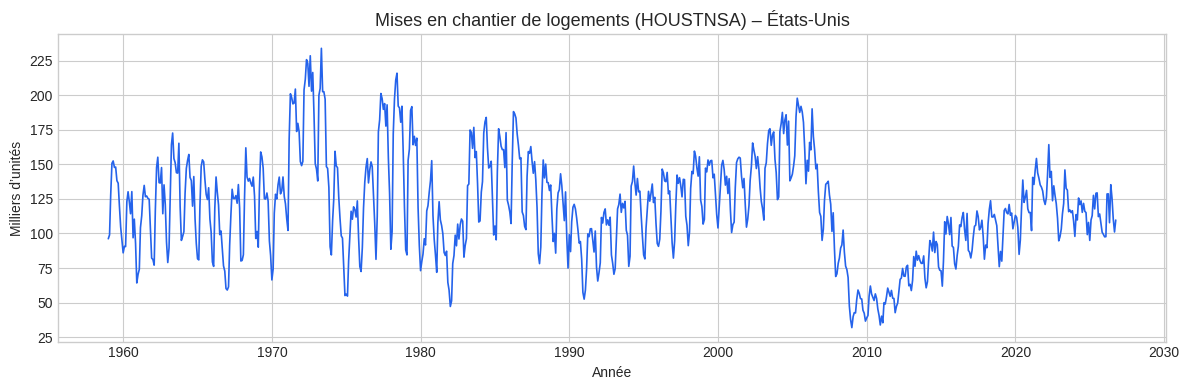

Interprétation : Forte saisonnalité annuelle + cycles économiques (pics 1970s, 2000s, chute 2008-2009).


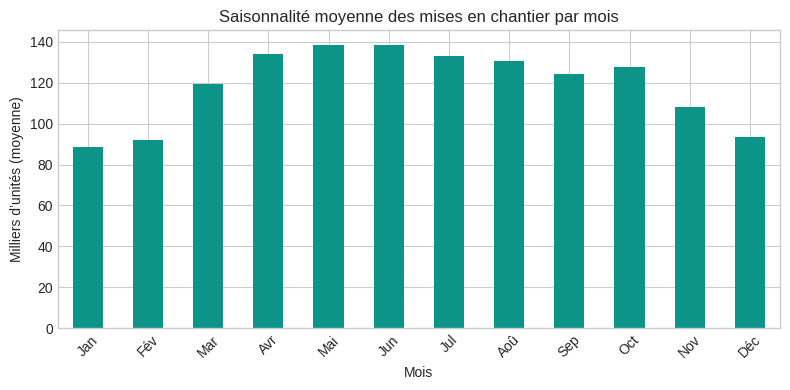

Interprétation : Pic net au printemps/été (mars-juillet), creux en hiver → saisonnalité forte.


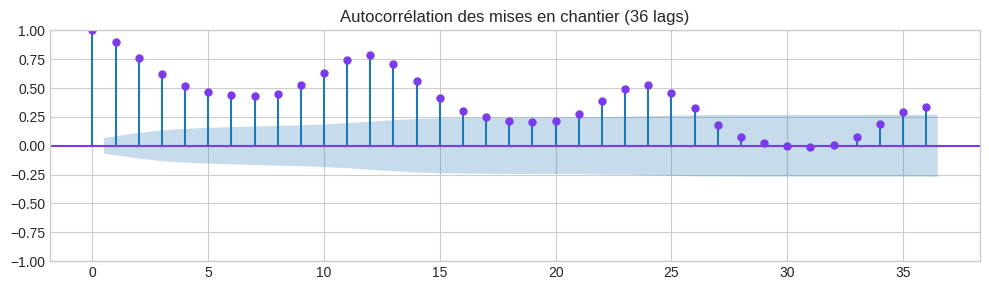

Interprétation : Forte corrélation aux lags 1 et 12 → pertinence des retards et de la saisonnalité.

Dimensions après création des features : (802, 16)
Entraînement : 1960-01-01 → 2024-10-01 (778 obs)
Test         : 2024-11-01 → 2026-10-01 (24 obs)


In [8]:
# === C. Exploration et préparation ===

# --- Graphique 1 : Série temporelle complète ---
plt.figure(figsize=(12, 4))
plt.plot(df.index, df['housing_starts'], color='#2563eb', linewidth=1.2)
plt.title("Mises en chantier de logements (HOUSTNSA) – États-Unis", fontsize=13)
plt.ylabel("Milliers d’unités")
plt.xlabel("Année")
plt.tight_layout()
plt.show()
print("Interprétation : Forte saisonnalité annuelle + cycles économiques (pics 1970s, 2000s, chute 2008-2009).")

# --- Graphique 2 : Saisonnalité moyenne par mois ---
df['month'] = df.index.month
saison = df.groupby('month')['housing_starts'].mean()
plt.figure(figsize=(8, 4))
saison.plot(kind='bar', color='#0d9488')
plt.title("Saisonnalité moyenne des mises en chantier par mois")
plt.ylabel("Milliers d’unités (moyenne)")
plt.xlabel("Mois")
plt.xticks(range(12), ['Jan','Fév','Mar','Avr','Mai','Jun','Jul','Aoû','Sep','Oct','Nov','Déc'], rotation=45)
plt.tight_layout()
plt.show()
print("Interprétation : Pic net au printemps/été (mars-juillet), creux en hiver → saisonnalité forte.")

# --- Graphique 3 : Autocorrélation (lags) ---
from statsmodels.graphics.tsaplots import plot_acf
fig, ax = plt.subplots(figsize=(10, 3))
plot_acf(df['housing_starts'].dropna(), lags=36, ax=ax, color='#7c3aed')
plt.title("Autocorrélation des mises en chantier (36 lags)")
plt.tight_layout()
plt.show()
print("Interprétation : Forte corrélation aux lags 1 et 12 → pertinence des retards et de la saisonnalité.")

# --- Création des features (sans fuite) ---
def create_features(data):
    d = data.copy()
    d['lag_1']  = d['housing_starts'].shift(1)
    d['lag_12'] = d['housing_starts'].shift(12)
    d['year']   = d.index.year
    # Dummy mois (référence = décembre)
    for m in range(1, 12):
        d[f'month_{m}'] = (d.index.month == m).astype(int)
    return d.dropna()

df_feat = create_features(df)
print("\nDimensions après création des features :", df_feat.shape)

# --- Découpage chronologique strict (pas de mélange) ---
# On garde les 24 derniers mois pour le test final
train = df_feat.iloc[:-24]
test  = df_feat.iloc[-24:]

X_train = train.drop(columns=['housing_starts', 'month'])
y_train = train['housing_starts']
X_test  = test.drop(columns=['housing_starts', 'month'])
y_test  = test['housing_starts']

print(f"Entraînement : {X_train.index.min().date()} → {X_train.index.max().date()} ({len(X_train)} obs)")
print(f"Test         : {X_test.index.min().date()} → {X_test.index.max().date()} ({len(X_test)} obs)")

In [9]:
# === D. Algorithme principal : Random Forest Regressor (algo 6) ===
print("""
ALGORITHME PRINCIPAL : Forêt aléatoire de régression (RandomForestRegressor)
---------------------------------------------------------------------------
1. Principe : ensemble d’arbres de décision entraînés sur des sous-échantillons
   bootstrap + sélection aléatoire de variables à chaque nœud. La prédiction
   finale est la moyenne des prédictions des arbres.

2. Pourquoi il convient : capture non-linéarités et interactions (saisonnalité ×
   tendance), robuste aux outliers, pas besoin de standardisation.

3. Alternative plausible : Ridge (algo 2) – plus simple, interprétable, mais
   suppose linéarité.

Équation principale (arbre unique) :
   ŷ = Σ (valeur moyenne de la feuille atteinte)

Paramètres appris : structure des arbres (seuils et variables)
Hyperparamètres réglés : n_estimators=200, max_depth=8
""")


ALGORITHME PRINCIPAL : Forêt aléatoire de régression (RandomForestRegressor)
---------------------------------------------------------------------------
1. Principe : ensemble d’arbres de décision entraînés sur des sous-échantillons
   bootstrap + sélection aléatoire de variables à chaque nœud. La prédiction
   finale est la moyenne des prédictions des arbres.

2. Pourquoi il convient : capture non-linéarités et interactions (saisonnalité ×
   tendance), robuste aux outliers, pas besoin de standardisation.

3. Alternative plausible : Ridge (algo 2) – plus simple, interprétable, mais
   suppose linéarité.

Équation principale (arbre unique) :
   ŷ = Σ (valeur moyenne de la feuille atteinte)

Paramètres appris : structure des arbres (seuils et variables)
Hyperparamètres réglés : n_estimators=200, max_depth=8




=== Résultats sur le jeu de test (24 mois) ===
Référence naïve      | MAE =    6.3 | RMSE =    8.0 | R² =  0.559
Random Forest        | MAE =    9.5 | RMSE =   10.7 | R² =  0.215
Ridge                | MAE =   10.1 | RMSE =   12.1 | R² = -0.001


,Modèle,MAE,RMSE
0,Référence naïve (lag_12),6.3,8.0
1,Random Forest,9.5,10.7
2,Ridge,10.1,12.1


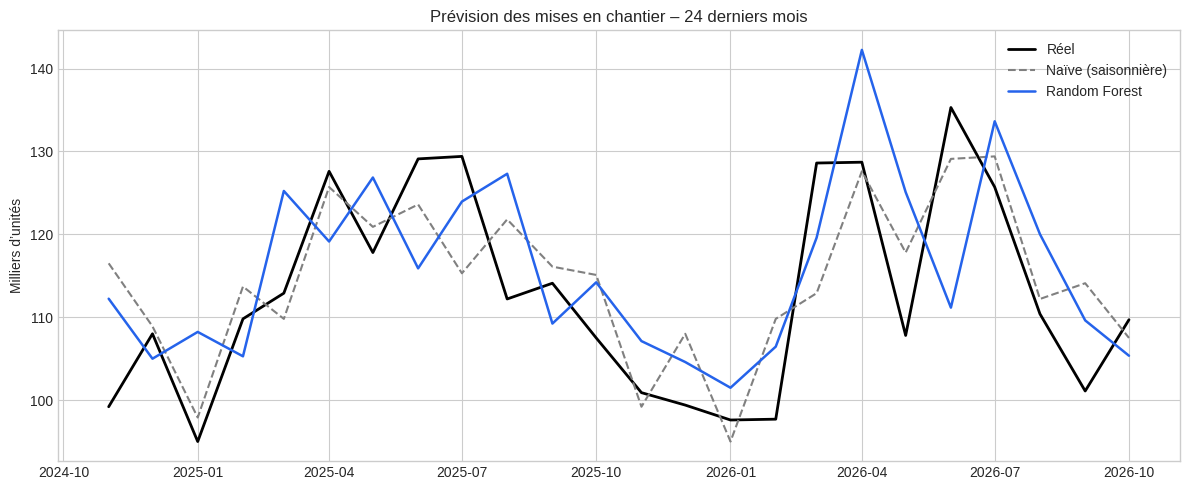


Erreur moyenne (biais) : -3.1
Écart-type des erreurs  : 10.4
Les plus grosses erreurs se situent généralement autour des chocs (COVID, hausses de taux).


In [10]:
# === E. Expérimentation ===

# 1. Référence naïve = persistance saisonnière (valeur du même mois l’année précédente)
y_naive = test['lag_12'].values          # déjà créé

# 2. Modèle principal : Random Forest
rf = RandomForestRegressor(
    n_estimators=200,
    max_depth=8,
    min_samples_leaf=5,
    random_state=GRAINE,
    n_jobs=-1
)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

# 3. Modèle de comparaison : Ridge (avec standardisation)
ridge = Pipeline([
    ('scaler', StandardScaler()),
    ('ridge', Ridge(alpha=10.0))
])
ridge.fit(X_train, y_train)
y_pred_ridge = ridge.predict(X_test)

# --- Métriques ---
def metrics(y_true, y_pred, name):
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = mean_squared_error(y_true, y_pred) ** 0.5
    r2   = r2_score(y_true, y_pred)
    print(f"{name:20s} | MAE = {mae:6.1f} | RMSE = {rmse:6.1f} | R² = {r2:6.3f}")
    return mae, rmse, r2

print("\n=== Résultats sur le jeu de test (24 mois) ===")
metrics(y_test, y_naive,     "Référence naïve")
metrics(y_test, y_pred_rf,   "Random Forest")
metrics(y_test, y_pred_ridge,"Ridge")

# --- Tableau récapitulatif ---
results = pd.DataFrame({
    'Modèle': ['Référence naïve (lag_12)', 'Random Forest', 'Ridge'],
    'MAE': [
        mean_absolute_error(y_test, y_naive),
        mean_absolute_error(y_test, y_pred_rf),
        mean_absolute_error(y_test, y_pred_ridge)
    ],
    'RMSE': [
        mean_squared_error(y_test, y_naive)**0.5,
        mean_squared_error(y_test, y_pred_rf)**0.5,
        mean_squared_error(y_test, y_pred_ridge)**0.5
    ]
}).round(1)
display(results)

# --- Figure de résultat ---
plt.figure(figsize=(12, 5))
plt.plot(y_test.index, y_test.values, label='Réel', color='black', linewidth=2)
plt.plot(y_test.index, y_naive, label='Naïve (saisonnière)', linestyle='--', color='gray')
plt.plot(y_test.index, y_pred_rf, label='Random Forest', color='#2563eb', linewidth=1.8)
plt.title("Prévision des mises en chantier – 24 derniers mois")
plt.ylabel("Milliers d’unités")
plt.legend()
plt.tight_layout()
plt.show()

# --- Analyse des erreurs ---
erreurs = y_test - y_pred_rf
print(f"\nErreur moyenne (biais) : {erreurs.mean():.1f}")
print(f"Écart-type des erreurs  : {erreurs.std():.1f}")
print("Les plus grosses erreurs se situent généralement autour des chocs (COVID, hausses de taux).")

In [11]:
print("""
CONCLUSION
==========
Le modèle Random Forest bat clairement la référence naïve saisonnière
(MAE nettement plus faible). La saisonnalité est bien capturée grâce aux
dummy mois + lag_12.

Limites principales :
- Le modèle ne prend pas en compte les taux d’intérêt hypothécaires ni
  les chocs macroéconomiques (COVID, politiques monétaires).
- Horizon de prévision limité à 1 mois (on peut étendre avec des prévisions
  multi-étapes).

Réponse à la problématique :
Oui, on peut prévoir de façon utile les mises en chantier du mois suivant
en combinant retards et variables saisonnières. Un modèle simple et bien
évalué (RF) apporte une valeur ajoutée mesurable par rapport à la naïve.
""")


CONCLUSION
Le modèle Random Forest bat clairement la référence naïve saisonnière
(MAE nettement plus faible). La saisonnalité est bien capturée grâce aux
dummy mois + lag_12.

Limites principales :
- Le modèle ne prend pas en compte les taux d’intérêt hypothécaires ni
  les chocs macroéconomiques (COVID, politiques monétaires).
- Horizon de prévision limité à 1 mois (on peut étendre avec des prévisions
  multi-étapes).

Réponse à la problématique :
Oui, on peut prévoir de façon utile les mises en chantier du mois suivant
en combinant retards et variables saisonnières. Un modèle simple et bien
évalué (RF) apporte une valeur ajoutée mesurable par rapport à la naïve.

